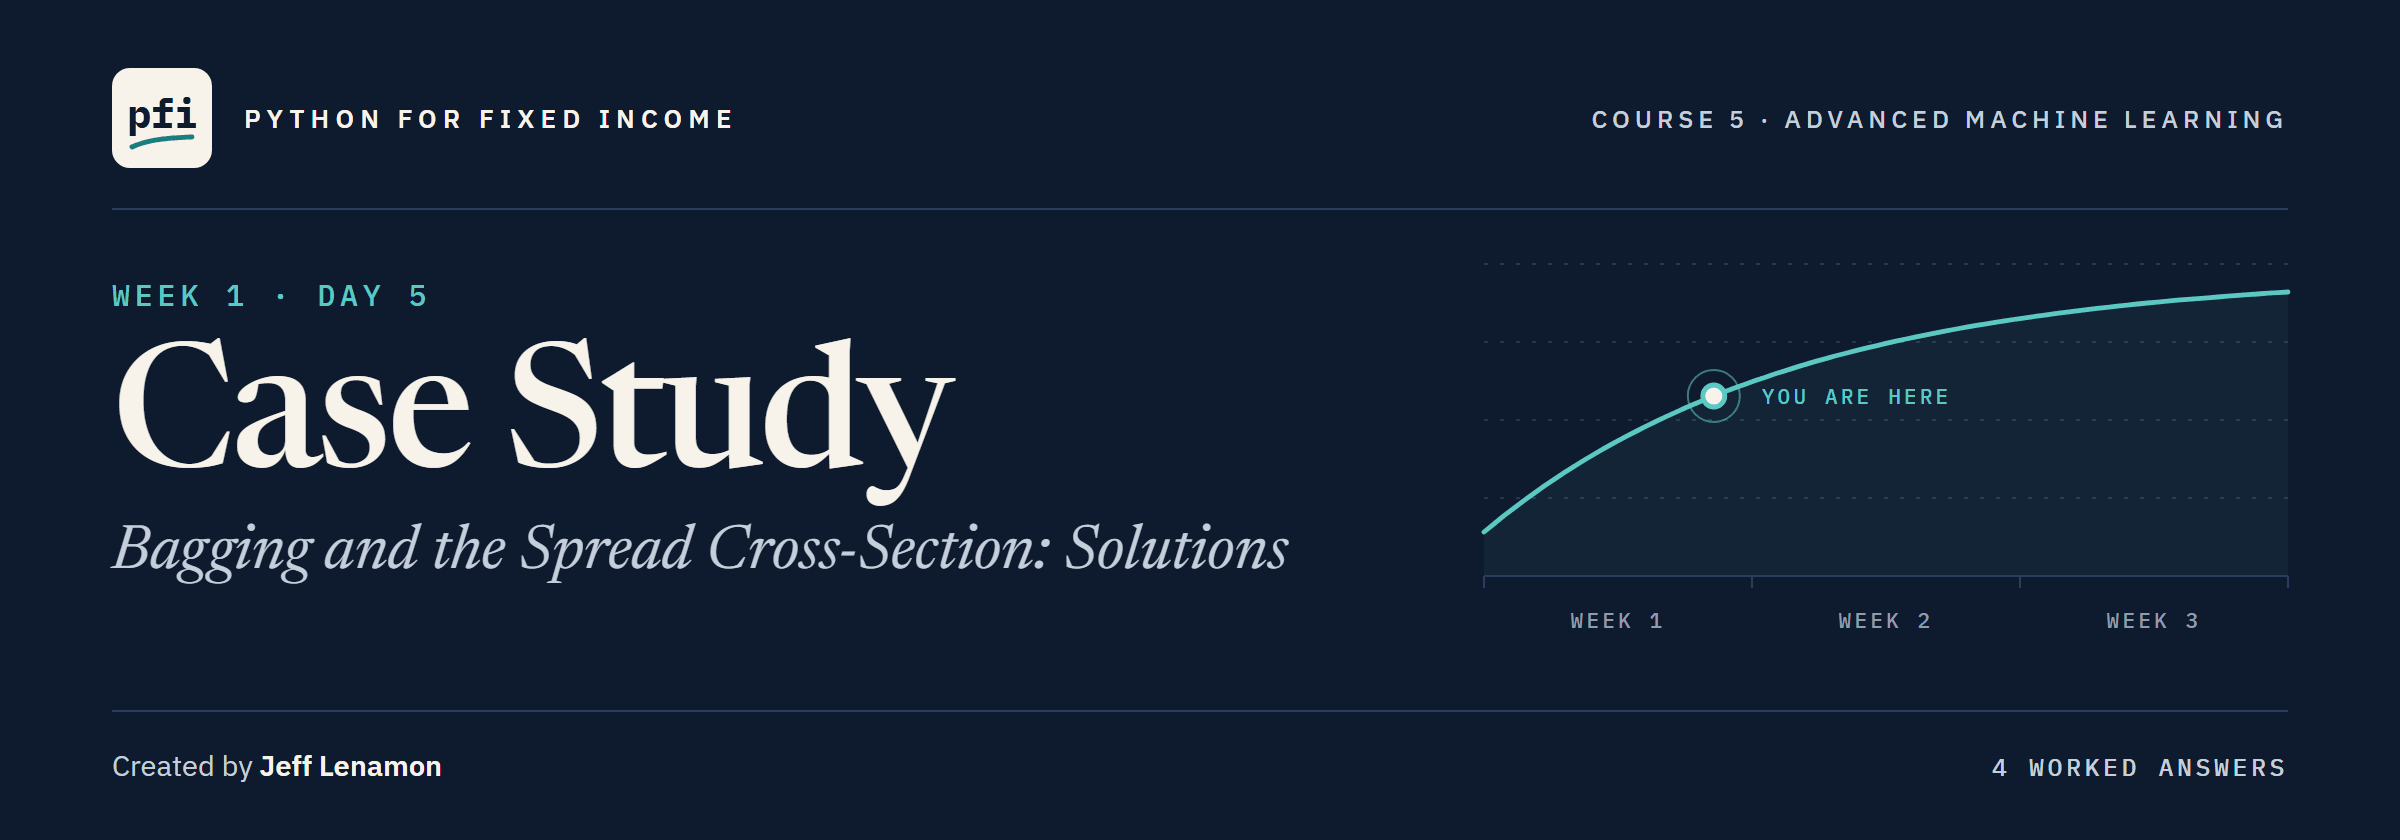

# Case Study: Bagging and the Spread Cross-Section: Solutions

Week 1, Day 5. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `benchmark.csv` and `ratings.csv`, 821 bonds of invented issuers: **synthetic**, made for this course by `tools/make_holdings.py`. No real issuer, price, or spread.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week1/day5/05_case_study_bagging_and_the_spread_cross_section_solutions.ipynb)

# Problem Statement

## Business Context

Course 4's Day 5 ended with a least squares model of log OAS, Course 4's line, scored in bp on five folds of its 615 training bonds.
Week 1 built bagging and random forests on the card file.
The desk now asks the same of the bonds: does an average of trees, which finds its own bends, describe them better than the line on the same five folds?
It wants the answer for a known issuer and for a new one, and what the forest leans on.
The bonds and issuers come from the course's generator, which Course 4 explained, so every fitted spread describes these rows, never a view on any bond.

## Objectives

Fit a regression tree and a forest on Course 4's folds and score them in bp.
Watch a forest's miss change as trees are averaged, read its out-of-bag score, and set its columns per split and leaf size by out-of-bag error.
Compare the forest with the line without and with coupon, and on folds that keep issuers whole.
Read permutation importance in bp and find the bonds the forest misses most.

## Data Dictionary

`benchmark.csv`, one row per bond, as in Course 4's Day 5:

1. `cusip`: the bond's identifier
2. `issuer` and `ticker`: the issuer's name and short code
3. `sector`: one of 10 industry sectors
4. `rating`: credit rating, AAA to CCC
5. `coupon`: annual coupon, percent of par
6. `maturity` and `as_of_date`: dates; years to maturity is built from them
7. `oas`: option-adjusted spread, bp; **the target is its log**
8. `duration`: modified duration, years
9. `amount_outstanding`: face value outstanding, dollars

`ratings.csv` adds `score` (1 for AAA up to 18 for CCC) and `grade`.

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and a dropdown
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# to split the bonds, fold the training bonds, and score on the folds
from sklearn.model_selection import train_test_split, KFold, GroupKFold, cross_validate, cross_val_predict

# Course 4's pipeline for the line, and the trees and forests
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor

# to measure misses in bp, and what a model leans on
from sklearn.metrics import mean_absolute_error, make_scorer
from sklearn.inspection import permutation_importance

# one look for every chart, and two decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:,.2f}".format)

# Loading the Data

## Reading the Bonds and Building Three Columns

Course 4's Day 5 cell, unchanged.

In [3]:
# the 821 bonds, and the table that turns each rating into a score and a grade
bonds = pd.read_csv(DATA + "benchmark.csv")
ratings = pd.read_csv(DATA + "ratings.csv")
data = bonds.merge(ratings[["rating", "score", "grade"]], on="rating")
rating_order = list(ratings["rating"])

# years to maturity, the amount in billions, and the target: the log of OAS
data["years_to_maturity"] = (pd.to_datetime(data["maturity"]) - pd.to_datetime(data["as_of_date"])).dt.days / 365.25
data["amount_bn"] = data["amount_outstanding"] / 1e9
data["log_oas"] = np.log(data["oas"])

## Splitting the Bonds First

In [4]:
# Course 4's split, with the seed: the same 615 training and 206 test bonds
train, test = train_test_split(data, test_size=0.25, random_state=SEED)
y = train["log_oas"]
print("Training bonds:", len(train), " Test bonds:", len(test))

Training bonds: 615  Test bonds: 206


**The 206 test bonds were Course 4's; this course never scores them. Everything below lives inside the 615.**

# Data Overview

## The Training Bonds

In [5]:
# the spread in bp and the numbers a model may use, on the training bonds
NUMBERS = ["score", "years_to_maturity", "duration", "amount_bn"]
train[["oas"] + NUMBERS + ["coupon"]].describe()

,oas,score,years_to_maturity,duration,amount_bn,coupon
count,615.00,615.00,615.00,615.00,615.00,615.00
mean,180.67,9.21,8.76,5.92,1.39,5.87
std,192.74,3.57,6.79,3.22,0.66,1.70
min,15.00,1.00,0.96,0.92,0.30,1.50
25%,77.00,7.00,4.03,3.45,0.85,4.75
50%,123.00,9.00,7.59,5.88,1.35,5.62
75%,212.00,11.00,10.66,7.65,1.95,6.81
max,"2,074.00",18.00,29.90,15.13,2.50,11.00


OAS runs from 15 to 2,074 bp, with a mean well above the median: the long right tail that made Course 4 model its log.

Years run from 1 to 30; the rating score from 1 to 18.

## Bonds per Issuer

In [6]:
# the share of high yield bonds, and how many training bonds each issuer has
print("High yield:", round((train["grade"] == "High Yield").mean() * 100, 1), "percent")
per_issuer = train.groupby("ticker").size()
print("Issuers:", len(per_issuer), " Bonds per issuer:", per_issuer.min(), "to", per_issuer.max(), " Median:", per_issuer.median())

High yield: 34.3 percent
Issuers: 149  Bonds per issuer: 1 to 8  Median: 4.0


About a third of the training bonds are high yield.

149 issuers hold 1 to 8 bonds each, and the bonds of one issuer share an issuer effect: that matters once folds keep issuers whole.

**Familiar bonds and familiar numbers. What we need is Course 4's line to beat.**

# Exploratory Data Analysis

## What Course 4 Found

OAS has a long right tail, so the target is its log (Day 4).

Each rating takes its own step (Day 2).

The generator caps maturity's effect at 10 years and never uses duration (Day 3).

Six bonds rated B or lower had their spreads multiplied by 2.5 to 4 after their coupons were set (Day 4).

Coupon carries part of the spread, and issuers hold much of the rest (Days 1, 4 and 5).

## Spread Against Maturity, Three Ratings

Q. Does a bond's spread climb with maturity in a straight line?

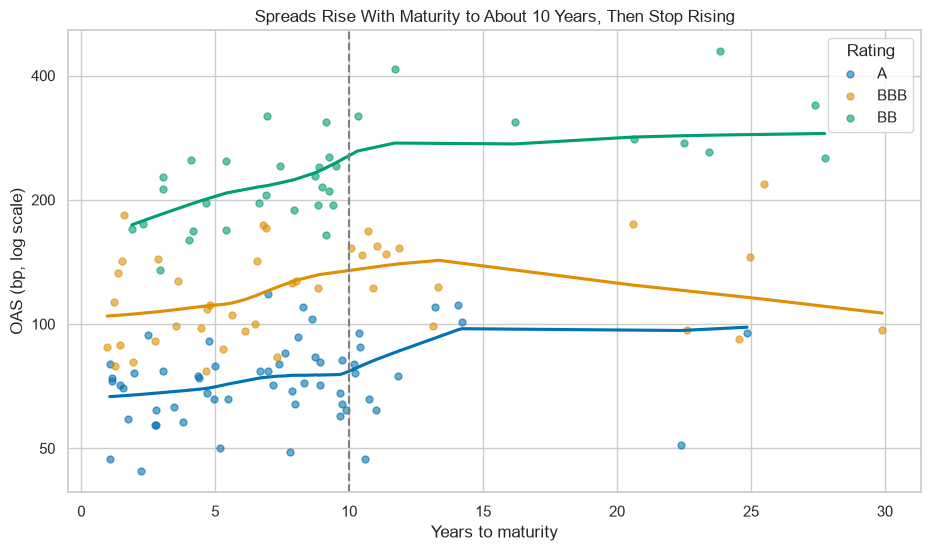

In [7]:
# OAS against years to maturity for three ratings, each with a lowess line; 10 years dashed
fig, ax = plt.subplots(figsize=(11, 6))
for rating in ["A", "BBB", "BB"]:
    rows = train[train["rating"] == rating]
    sns.regplot(x=rows["years_to_maturity"], y=rows["oas"], lowess=True, ci=None, label=rating, ax=ax,
                scatter_kws={"alpha": 0.6, "s": 25})
ax.axvline(10, color="gray", linestyle="--")
ax.set_yscale("log")

# plain bp labels on the log axis: set_yticks takes the ticks and their labels, minorticks_off drops the rest
ax.set_yticks([50, 100, 200, 400], [50, 100, 200, 400])
ax.minorticks_off()
ax.set_xlabel("Years to maturity")
ax.set_ylabel("OAS (bp, log scale)")
ax.set_title("Spreads Rise With Maturity to About 10 Years, Then Stop Rising")
ax.legend(title="Rating")
plt.show()

In [8]:
# median OAS in bp by maturity band, one row per rating
three = train[train["rating"].isin(["A", "BBB", "BB"])]
bands = pd.cut(three["years_to_maturity"], [0, 3, 6, 10, 15, 31])
three.groupby(["rating", bands], observed=True)["oas"].median().unstack()

years_to_maturity,"(0, 3]","(3, 6]","(6, 10]","(10, 15]","(15, 31]"
rating,,,,,
A,70.00,68.00,77.00,80.00,73.00
BB,170.00,204.00,215.00,367.50,281.00
BBB,102.00,102.00,126.00,148.00,121.00


BBB rises from 102 bp under 6 years to 148 at 10 to 15 years, then sits at 121 beyond 15.

BB rises from 170 to 367.5, then sits at 281; A stays between 68 and 80.

**Spreads rise to about 10 years and then stop. A straight line in years cannot stop; a tree can.**

# Data Preparation for Modeling

## Inputs for the Trees

The file's ten sectors are fixed in advance, so their indicator columns learn nothing from the rows and can be made before the folds.

In [9]:
# the trees' inputs: the four numbers as they stand, then one indicator column per sector
X = pd.concat([train[NUMBERS], pd.get_dummies(train["sector"], dtype=float)], axis=1)
print(X.shape)
print(list(X.columns))

(615, 14)
['score', 'years_to_maturity', 'duration', 'amount_bn', 'Consumer', 'Energy', 'Financials', 'Health Care', 'Industrials', 'Materials', 'Technology', 'Telecom', 'Transportation', 'Utilities']


A tree splits a number as it stands, so nothing is scaled.

The rating enters as its score, so one split can separate every rating below a notch from every rating above it.

Coupon waits for the comparison.

## The Folds and the Miss in bp

Course 4's Day 5 folds, its `mae_bp` and its `bp_scorer`, unchanged.

In [10]:
# five folds of the training bonds, shuffled with the seed
folds = KFold(n_splits=5, shuffle=True, random_state=SEED)

# the miss in bp: both logs go back through exp first
def mae_bp(y_log, fitted_log):
    return mean_absolute_error(np.exp(y_log), np.exp(fitted_log))

bp_scorer = make_scorer(mae_bp, greater_is_better=False)

## The Line to Beat

Course 4's Day 5 pipeline, repeated as one cell.

In [11]:
# rating and sector as indicator columns (A and Consumer left out), the numbers scaled, then the regressor
sectors = sorted(data["sector"].unique())

def make_model(regressor, numbers):
    steps = [("categories", OneHotEncoder(categories=[rating_order, sectors], drop=["A", "Consumer"], sparse_output=False),
              ["rating", "sector"]),
             ("numbers", StandardScaler(), numbers)]
    return Pipeline([("prep", ColumnTransformer(steps)), ("model", regressor)])

`return_train_score=True` makes `cross_validate` also score each fold's model on the 492 bonds it was fitted on, the **fitted folds**, kept in `["train_score"]`.

In [12]:
# the line without coupon: its miss on each held-out fold, and on the bonds each fold was fitted on
LINE_NUMBERS = ["years_to_maturity", "duration", "amount_bn"]
LINE_X = train[["rating", "sector"] + LINE_NUMBERS]
line = make_model(LinearRegression(), LINE_NUMBERS)
scores = cross_validate(line, LINE_X, y, cv=folds, scoring=bp_scorer, return_train_score=True, n_jobs=1)
held = {"line": -scores["test_score"]}
fitted = {"line": -scores["train_score"].mean()}
print("Held-out folds:", held["line"].round(1), " Mean:", round(held["line"].mean(), 2), "bp")
print("Fitted folds, mean:", round(fitted["line"], 2), "bp")

Held-out folds: [30.1 36.2 61.8 39.3 41.2]  Mean: 41.72 bp
Fitted folds, mean: 39.09 bp


Every model in this notebook is fitted and scored inside Course 4's 615 training bonds; Course 4's 206 test bonds are never scored in this course.

The line misses a held-out bond by 41.72 bp on average, from 30.1 to 61.8 bp fold by fold.

It misses its own bonds by 39.09, close to the held-out miss: a line has little room to memorise.

**Course 4's line misses a held-out bond by 41.7 bp and its own bonds by 39.1. Now one tree.**

# One Regression Tree

## A Full Tree

`DecisionTreeRegressor` is Course 4's Day 11 tree: each leaf hands back the average log OAS of the training bonds in it.
Left without a limit, it keeps splitting until each leaf is pure.

**Predict 1**

The line misses its own bonds by 39.1 bp and a held-out bond by 41.7.

Q. Write down both numbers for a full tree.

In [13]:
# a full tree on the same five folds
full_tree = DecisionTreeRegressor(random_state=SEED)
scores = cross_validate(full_tree, X, y, cv=folds, scoring=bp_scorer, return_train_score=True, n_jobs=1)
held["full tree"] = -scores["test_score"]
fitted["full tree"] = -scores["train_score"].mean()
print("Held-out folds, mean:", round(held["full tree"].mean(), 2), "bp")

# abs drops the minus sign the scorer leaves on a miss of exactly zero
print("Fitted folds, mean:", abs(round(fitted["full tree"], 2)), "bp")

Held-out folds, mean: 51.93 bp
Fitted folds, mean: 0.0 bp


In [14]:
# the full tree fitted on all 615 bonds: its depth, its leaves and its first question
full_tree.fit(X, y)
print("Depth:", full_tree.get_depth(), " Leaves:", full_tree.get_n_leaves())
print("First question:", X.columns[full_tree.tree_.feature[0]], "<=", full_tree.tree_.threshold[0])

Depth: 20  Leaves: 611
First question: score <= 9.5


### Interpretation of the Full Tree

It misses its own bonds by nothing and a held-out bond by 51.93 bp, 10 bp worse than the line.

611 leaves for 615 bonds: a new bond's fitted spread is mostly one training bond's spread.

Its first question is the rating score, splitting BBB and better from BBB- and worse.

## A Shallow Tree

In [15]:
# a tree allowed four questions on any path
shallow_tree = DecisionTreeRegressor(max_depth=4, random_state=SEED)
scores = cross_validate(shallow_tree, X, y, cv=folds, scoring=bp_scorer, return_train_score=True, n_jobs=1)
held["depth-4 tree"] = -scores["test_score"]
fitted["depth-4 tree"] = -scores["train_score"].mean()
print("Leaves:", shallow_tree.fit(X, y).get_n_leaves())
print("Held-out:", round(held["depth-4 tree"].mean(), 2), " Fitted:", round(fitted["depth-4 tree"], 2), "bp")

Leaves: 16
Held-out: 45.21  Fitted: 40.43 bp


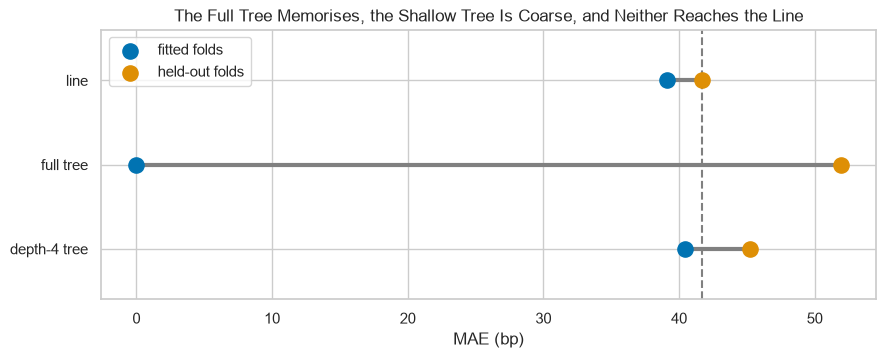

In [16]:
# Day 1's dumbbell: fitted folds against held-out folds, one row per model, the line's held-out miss dashed
gap = pd.DataFrame({"fitted": fitted, "held out": {name: held[name].mean() for name in fitted}})
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hlines(gap.index, gap["fitted"], gap["held out"], color="gray", linewidth=3)
ax.scatter(gap["fitted"], gap.index, s=120, label="fitted folds", zorder=3)
ax.scatter(gap["held out"], gap.index, s=120, label="held-out folds", zorder=3)
ax.axvline(held["line"].mean(), color="gray", linestyle="--")
ax.set(ylim=(2.6, -0.6), xlabel="MAE (bp)")
ax.set_title("The Full Tree Memorises, the Shallow Tree Is Coarse, and Neither Reaches the Line")
ax.legend(loc="upper left")
plt.show()

The depth-4 tree has 16 leaves, about 38 bonds each: its two misses sit close together, both above the line's.

The full tree's dumbbell is the widest: from nothing to 51.9 bp.

**The full tree memorises and the shallow tree is too coarse. Day 1's answer: average many full trees.**

# Averaging Trees

## Bagging and the Forest

![One bond goes down tree 1, tree 2 and on to tree 100; in each it lands in one leaf, whose value is the average log OAS of the training bonds in that leaf, mostly one bond for a full tree; the forest averages the 100 values and exp turns the average into the fitted spread in bp](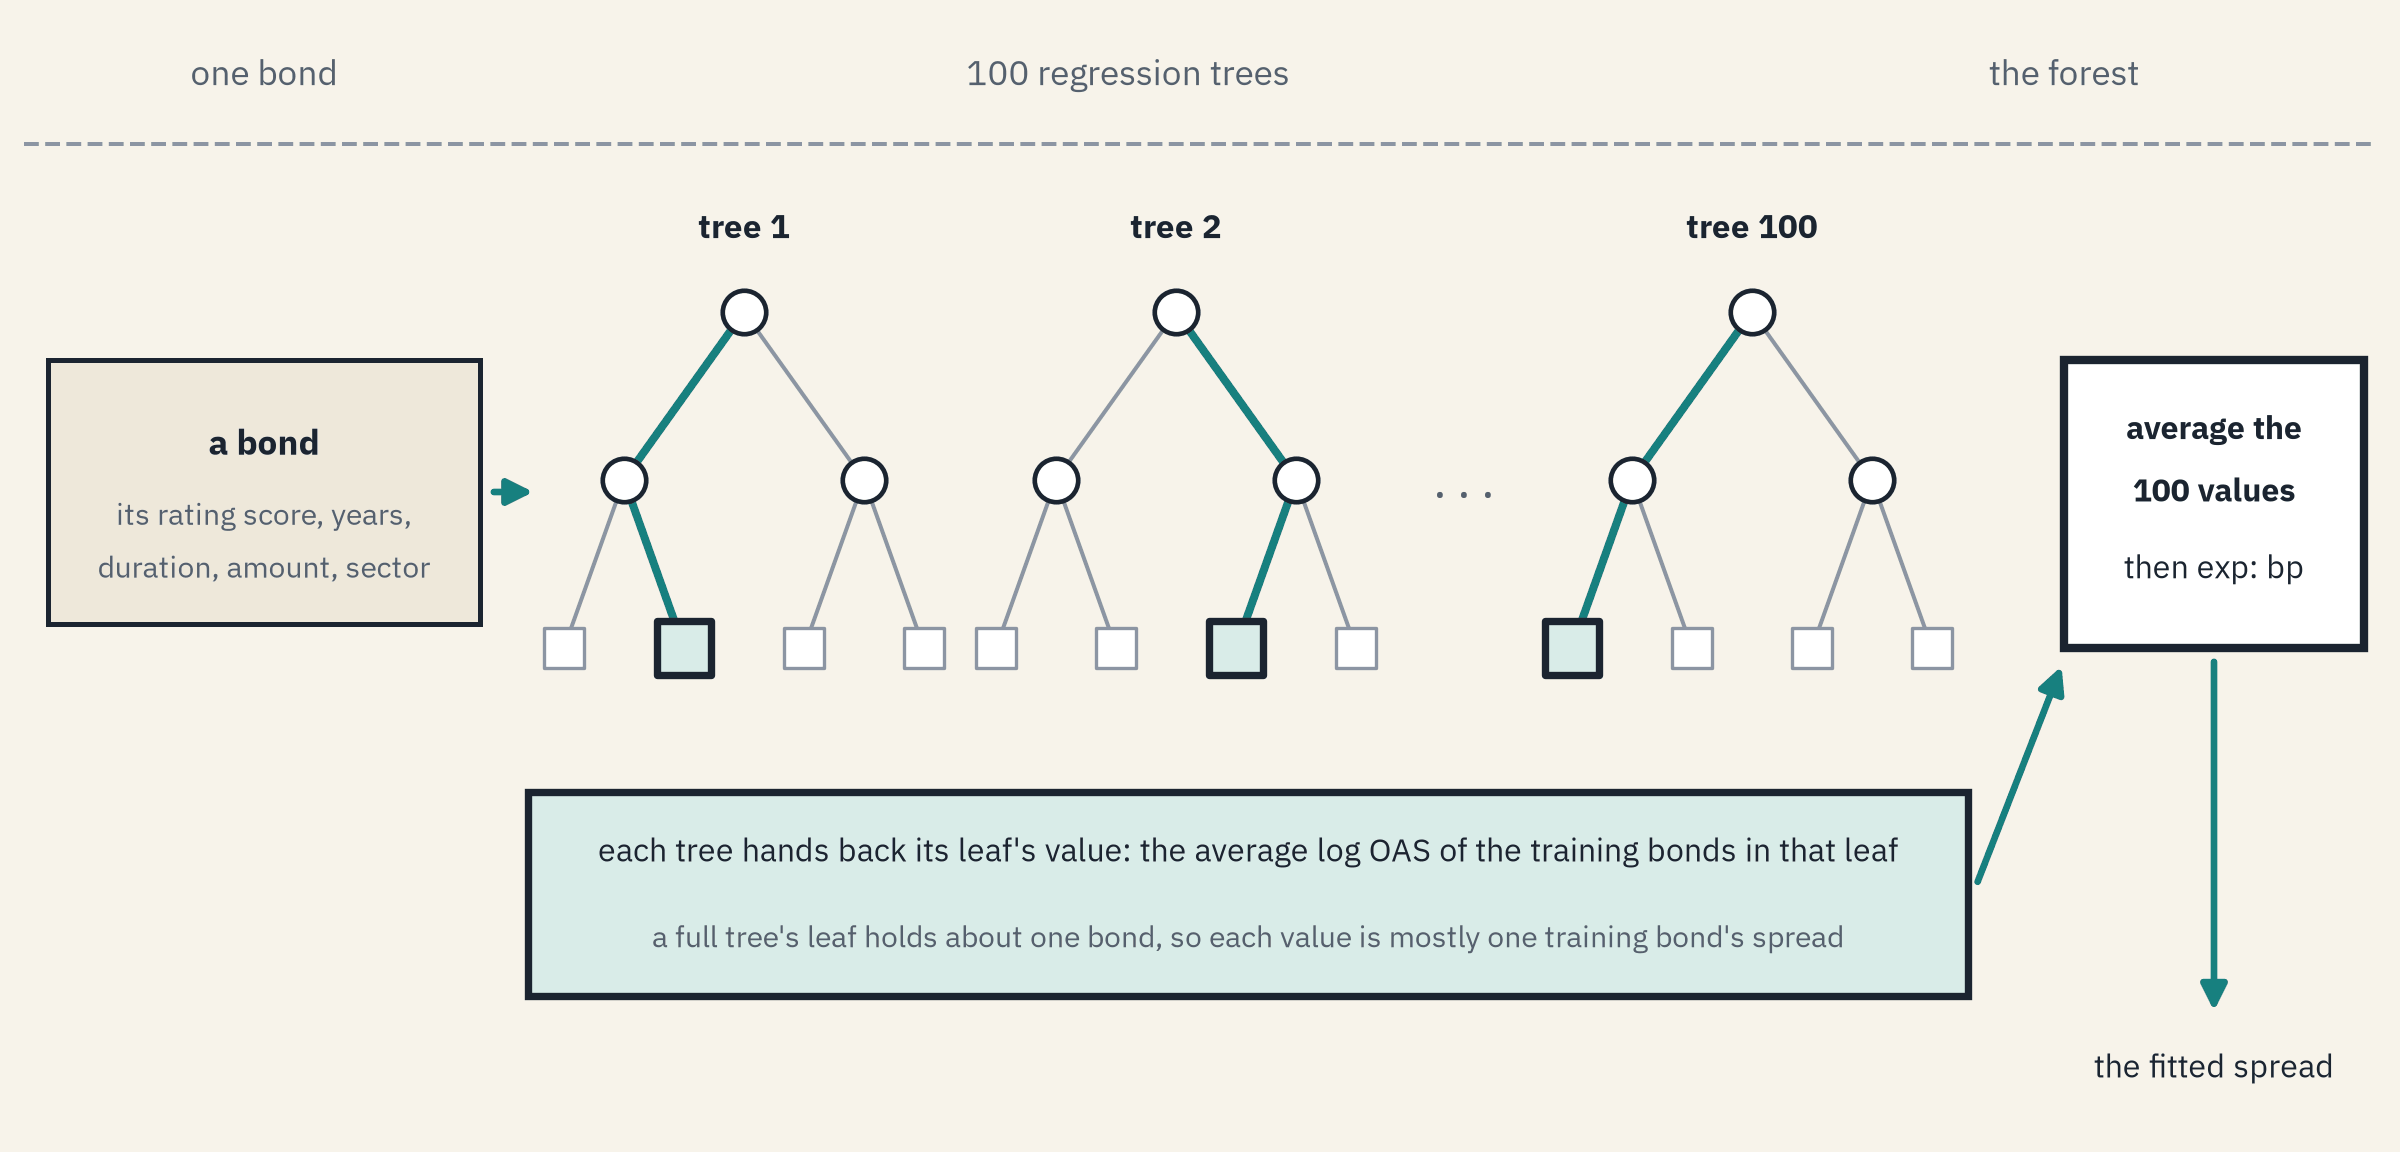)

`BaggingRegressor` and `RandomForestRegressor` are the regression twins of Day 2's and Day 3's classifiers.
Each averages its trees' outputs, here logs of OAS.

In [17]:
# Day 2's bagging and Day 3's forest, each with 100 full regression trees
bagging = BaggingRegressor(DecisionTreeRegressor(random_state=SEED), n_estimators=100, random_state=SEED, n_jobs=1)
forest = RandomForestRegressor(random_state=SEED, n_jobs=1)
for name, model in [("bagging", bagging), ("forest", forest)]:
    scores = cross_validate(model, X, y, cv=folds, scoring=bp_scorer, return_train_score=True, n_jobs=1)
    held[name] = -scores["test_score"]
    fitted[name] = -scores["train_score"].mean()
    print(name, " Held-out:", round(held[name].mean(), 2), " Fitted:", round(fitted[name], 2), "bp")
print("Share of the columns each split of the forest may use:", forest.max_features)

bagging  Held-out: 40.26  Fitted: 16.69 bp
forest  Held-out: 40.23  Fitted: 16.69 bp
Share of the columns each split of the forest may use: 1.0


Both pass the line: 40.26 and 40.23 bp against 41.72.

They agree because the regressor's default `max_features` is 1.0: every split may use every column, so this forest is bagging.

**A hundred full trees, each worse than the line, average to a model that beats it by 1.5 bp.**

## Averaging One Tree at a Time

One full tree misses by 51.9 bp and 100 of them by 40.2.

**Predict 2**

Q. How many trees must be averaged before the forest's held-out miss falls below the line's 41.72 bp? Write down a number.

In [18]:
# in each fold: every tree's output on the held-out bonds, then the miss of the average of the first k trees
K = np.arange(1, 101)
running, single = [], []
for fit_rows, held_rows in folds.split(X):
    fold_forest = RandomForestRegressor(random_state=SEED, n_jobs=1).fit(X.iloc[fit_rows], y.iloc[fit_rows])
    outputs = np.column_stack([tree.predict(X.iloc[held_rows].to_numpy()) for tree in fold_forest.estimators_])
    averages = outputs.cumsum(axis=1) / K
    running.append([mae_bp(y.iloc[held_rows], averages[:, k - 1]) for k in K])
    single += [mae_bp(y.iloc[held_rows], outputs[:, j]) for j in range(100)]
running = pd.DataFrame(running, columns=K).T

In [19]:
# the mean over the five folds at a few sizes, and the first size below the line
mean_curve = running.mean(axis=1)
print(mean_curve[[1, 2, 3, 5, 8, 10, 20, 50, 100]].round(2).to_dict())
print("First size below the line:", mean_curve[mean_curve < held["line"].mean()].index[0], "trees")
print("500 single trees:", round(min(single), 1), "to", round(max(single), 1), "bp, mean", round(np.mean(single), 1))

{1: 55.94, 2: 47.82, 3: 46.54, 5: 42.89, 8: 41.39, 10: 40.95, 20: 40.44, 50: 39.56, 100: 40.23}
First size below the line: 8 trees
500 single trees: 36.1 to 98.8 bp, mean 57.5


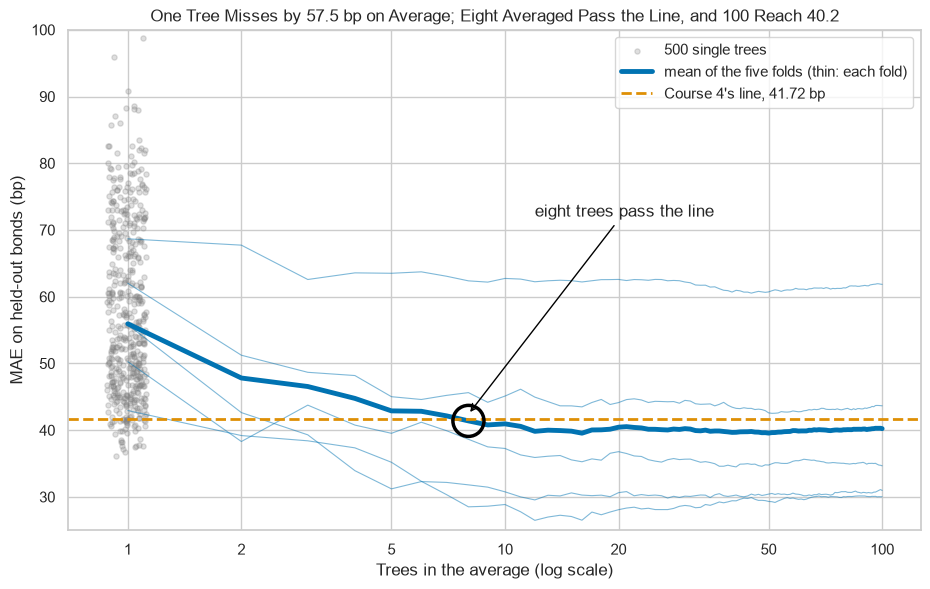

In [20]:
# single trees as a gray cloud at one tree, each fold's running miss thin, their mean bold, the line dashed
rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.scatter(1 + rng.uniform(-0.12, 0.12, len(single)), single, color="gray", alpha=0.25, s=14, label="500 single trees")
ax.plot(running.index, running, color="C0", linewidth=0.8, alpha=0.5)
ax.plot(mean_curve.index, mean_curve, color="C0", linewidth=3.5, label="mean of the five folds (thin: each fold)")
ax.axhline(held["line"].mean(), color="C1", linestyle="--", linewidth=2, label="Course 4's line, 41.72 bp")
ax.scatter(8, mean_curve[8], s=500, facecolor="none", edgecolor="black", linewidth=2.5, zorder=4)
ax.annotate("eight trees pass the line", (8, mean_curve[8] + 1), xytext=(12, 72), arrowprops={"arrowstyle": "->", "color": "black"})
ax.set_xscale("log")
ax.set_xticks([1, 2, 5, 10, 20, 50, 100], [1, 2, 5, 10, 20, 50, 100])
ax.set(xlabel="Trees in the average (log scale)", ylabel="MAE on held-out bonds (bp)", ylim=(25, 100))
ax.set_title("One Tree Misses by 57.5 bp on Average; Eight Averaged Pass the Line, and 100 Reach 40.2")
ax.legend(loc="upper right")
plt.show()

A single tree misses a held-out fold by 36.1 to 98.8 bp: the gray cloud.

The first trees added do the most: 55.9 bp for each fold's first tree alone, 47.8 for the first two, 42.9 for five.

From eight trees the average stays below the line; after about 20 the curve is flat.

The thin lines are the five folds: the fold with the widest bonds sits highest at every size.

## The Out-of-Bag Rows

Day 2's out-of-bag rows work the same way for a regressor.
`oob_score=True` keeps each bond's **out-of-bag output** in `.oob_prediction_`: the average of the trees whose samples left it out.
For a regressor `.oob_score_` is the R-squared of log OAS on those outputs, not an accuracy as on Day 2.

**Predict 3**

The forest misses held-out bonds by 40.23 bp on five folds, from five fits.

Q. From one fit on all 615 bonds, what is its out-of-bag MAE in bp? Write down a number.

In [21]:
# one forest on all 615 bonds, keeping each bond's out-of-bag output
oob_forest = RandomForestRegressor(oob_score=True, random_state=SEED, n_jobs=1).fit(X, y)
print("oob_score_ (R-squared, log OAS):", round(oob_forest.oob_score_, 4))
print("Out-of-bag MAE:", round(mae_bp(y, oob_forest.oob_prediction_), 2), "bp")
print("In-sample MAE:", round(mae_bp(y, oob_forest.predict(X)), 2), "bp")

oob_score_ (R-squared, log OAS): 0.8858
Out-of-bag MAE: 40.81 bp
In-sample MAE: 16.45 bp


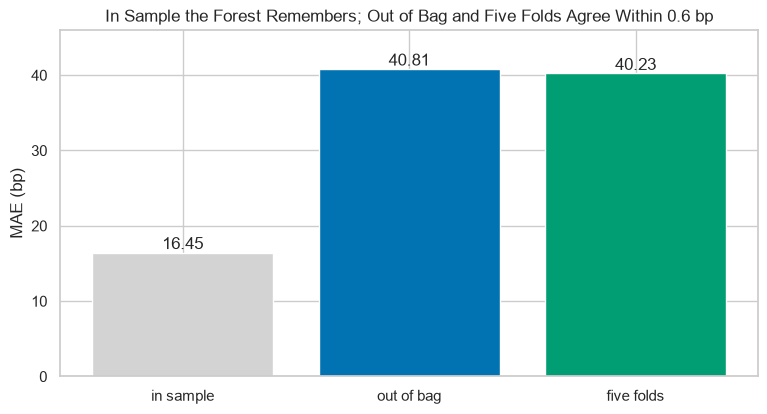

In [22]:
# one forest scored three ways, in bp
three_ways = pd.Series({"in sample": mae_bp(y, oob_forest.predict(X)),
                        "out of bag": mae_bp(y, oob_forest.oob_prediction_),
                        "five folds": held["forest"].mean()})
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(three_ways.index, three_ways.values, color=["lightgray", "C0", "C2"])
ax.bar_label(bars, fmt="%.2f")
ax.set(ylabel="MAE (bp)", ylim=(0, 46))
ax.set_title("In Sample the Forest Remembers; Out of Bag and Five Folds Agree Within 0.6 bp")
plt.show()

Each bond sits in about 63 of the 100 samples (Day 1's two thirds), so the in-sample miss is memory.

The out-of-bag miss needs one fit and no folds, and lands 0.58 bp above the folds' 40.23.

**Averaging takes one tree from 51.9 bp to 40.2 and past the line from eight trees. Two settings shape each tree, and the out-of-bag rows can choose them without the folds.**

# Model Performance Improvement

## Columns per Split

Day 3's `max_features` sets the share of the columns each split may use.
The regressor's default, 1.0, uses all 14; `"sqrt"`, the classifier's default, offers 3 of the 14.

**Predict 4**

Q. Write down the held-out MAE of the same forest with `max_features="sqrt"`.

In [23]:
# the same forest, each split offered 3 of the 14 columns
sqrt_forest = RandomForestRegressor(max_features="sqrt", random_state=SEED, n_jobs=1)
sqrt_held = -cross_validate(sqrt_forest, X, y, cv=folds, scoring=bp_scorer, n_jobs=1)["test_score"]
print("Held-out mean:", round(sqrt_held.mean(), 2), "bp")

Held-out mean: 45.8 bp


Q. How often does each forest's first question use the rating?

In [24]:
# each tree's first question (Day 1's tree_.feature[0]) in forests offered all, three quarters, half and sqrt of the columns
first = {}
for share in [1.0, 0.75, 0.5, "sqrt"]:
    shaped = RandomForestRegressor(max_features=share, random_state=SEED, n_jobs=1).fit(X, y)
    first[str(share)] = pd.Series([X.columns[tree.tree_.feature[0]] for tree in shaped.estimators_]).value_counts()
first = pd.DataFrame(first).fillna(0)
first.loc["score"]

1.0    100.00
0.75    68.00
0.5     52.00
sqrt    26.00
Name: score, dtype: float64

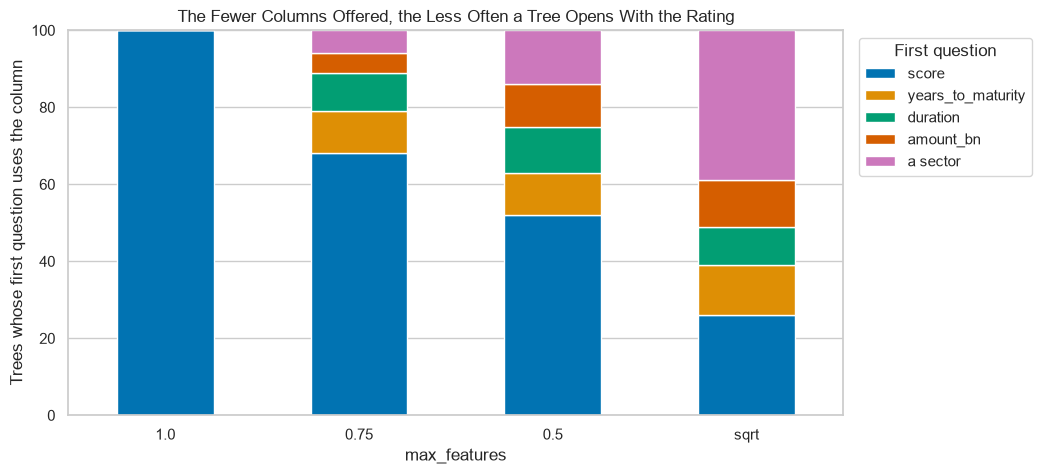

In [25]:
# first questions in five groups, as 100 percent stacked bars (each forest has 100 trees)
groups = first.loc[["score", "years_to_maturity", "duration", "amount_bn"]]
groups.loc["a sector"] = first.drop(index=NUMBERS).sum()
ax = groups.T.plot.bar(stacked=True, figsize=(10, 5), rot=0)
ax.set(xlabel="max_features", ylabel="Trees whose first question uses the column")
ax.set_title("The Fewer Columns Offered, the Less Often a Tree Opens With the Rating")
ax.legend(title="First question", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

At 1.0 every tree opens with the rating score; at `"sqrt"`, 26 of 100 do.

The rating carries most of the spread, and three columns at a time often hide it from a split.

## Leaf Size and the Shape of the Fit

Day 3's `min_samples_leaf` sets the fewest training bonds a leaf may hold.
To see the shape it gives, we fit forests on two columns only, score and years, and draw each tree's fitted spread for a BBB bond (score 9) from 0.5 to 30 years: a picture, not a score.

In [26]:
# forests on two columns at six leaf sizes: every tree's output in logs for a BBB bond along 120 maturities
TWO = ["score", "years_to_maturity"]
grid = pd.DataFrame({"score": 9.0, "years_to_maturity": np.linspace(0.5, 30, 120)})
curves = {}
for leaf in [1, 2, 5, 10, 20, 50]:
    two_forest = RandomForestRegressor(min_samples_leaf=leaf, random_state=SEED, n_jobs=1).fit(train[TWO], y)
    curves[leaf] = np.column_stack([tree.predict(grid.to_numpy()) for tree in two_forest.estimators_])
two_line = np.exp(LinearRegression().fit(train[TWO], y).predict(grid))

In [27]:
# the forest's fitted spread in bp at 1, 10 and 30 years for each leaf size, and the two-column line's
at = [np.abs(grid["years_to_maturity"] - years).argmin() for years in [1, 10, 30]]
shape = pd.DataFrame({leaf: np.exp(curves[leaf].mean(axis=1))[at] for leaf in curves}, index=["1 year", "10 years", "30 years"]).T
shape.loc["line"] = two_line[at]
shape

,1 year,10 years,30 years
1,92.81,150.26,117.67
2,96.54,146.05,137.50
5,107.08,141.40,127.15
10,104.80,133.97,131.71
20,111.22,127.02,126.61
50,116.93,118.62,118.62
line,116.85,127.31,154.43


In [28]:
# the 100 trees thin, their average bold, the two-column line dashed, the BBB training bonds as dots
bbb = train[train["rating"] == "BBB"]

def draw_trees(leaf, ax):
    ax.plot(grid["years_to_maturity"], np.exp(curves[leaf]), color="gray", linewidth=0.5, alpha=0.3)
    ax.plot(grid["years_to_maturity"], np.exp(curves[leaf].mean(axis=1)), color="C0", linewidth=3, label="average of 100 trees")
    ax.plot(grid["years_to_maturity"], two_line, color="C1", linestyle="--", linewidth=2, label="two-column line")
    ax.scatter(bbb["years_to_maturity"], bbb["oas"], color="black", s=16, zorder=3, label="BBB training bonds")
    ax.set(ylim=(40, 320), xlabel="Years to maturity", ylabel="Fitted OAS for a BBB bond (bp)")
    ax.set_title(f"min_samples_leaf={leaf}")

Pick a leaf size and watch the gray trees and their average.

In [29]:
# your turn: pick a leaf size
def show_trees(leaf=1):
    fig, ax = plt.subplots(figsize=(10, 5.5))
    draw_trees(leaf, ax)
    ax.legend(loc="upper left")
    plt.show()

interact(show_trees, leaf=[1, 2, 5, 10, 20, 50]);

interactive(children=(Dropdown(description='leaf', options=(1, 2, 5, 10, 20, 50), value=1), Output()), _dom_cl…

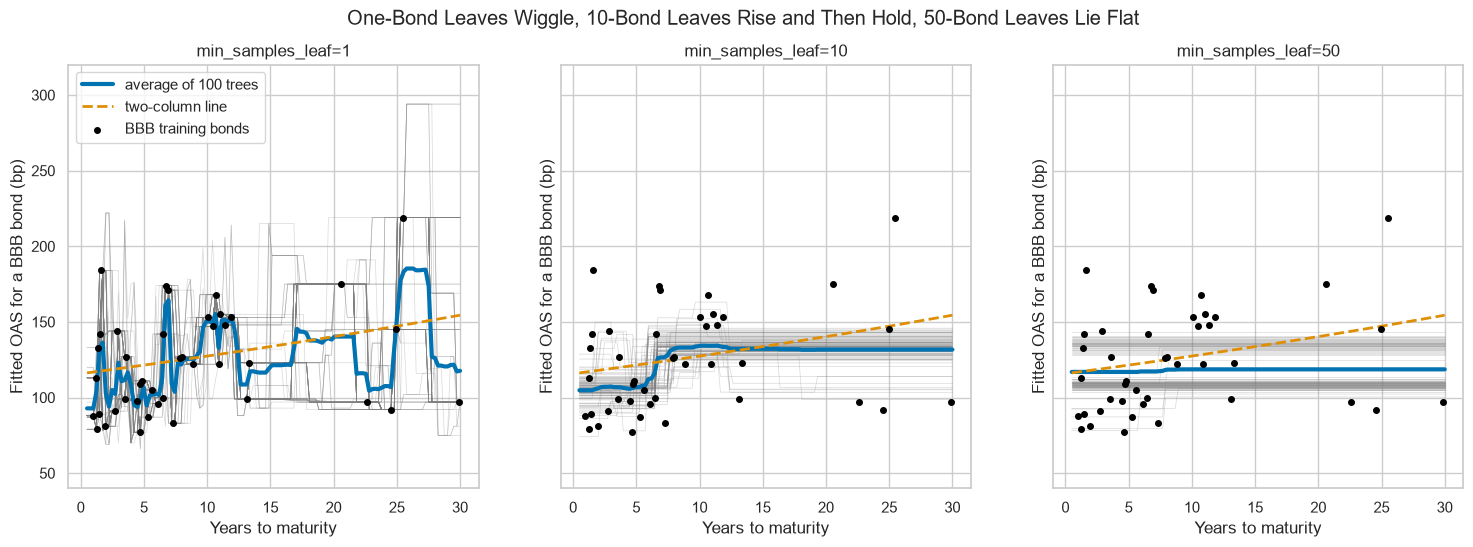

In [30]:
# the dropdown's starting leaf size beside 10 and 50, drawn as a still picture (dropdowns do not run on GitHub)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
for leaf, ax in zip([1, 10, 50], axes):
    draw_trees(leaf, ax)
axes[0].legend(loc="upper left")
fig.suptitle("One-Bond Leaves Wiggle, 10-Bond Leaves Rise and Then Hold, 50-Bond Leaves Lie Flat")
plt.show()

This is a **spaghetti chart**: every tree's curve drawn thin, so their spread shows, and their average drawn bold.

With one-bond leaves each tree jumps from bond to bond, and the average still wiggles: 92.8 bp at 1 year, 150.3 at 10, 117.7 at 30.

With 10-bond leaves the average rises to 134.0 by 10 years and stays near it, the generator's cap.

The line keeps climbing, 116.9 to 154.4, because it cannot stop; with 50-bond leaves the forest hardly moves at all.

## Choosing Both by Out-of-Bag Error

Each forest is fitted once on all 615 bonds and judged by its out-of-bag MAE, so no fold is touched.

In [31]:
# 30 forests: six column shares by five leaf sizes, each judged by its out-of-bag MAE in bp
rows = []
for share in [0.2, 0.33, 0.5, 0.75, 1.0, "sqrt"]:
    for leaf in [1, 2, 5, 10, 20]:
        grid_forest = RandomForestRegressor(max_features=share, min_samples_leaf=leaf, oob_score=True,
                                            random_state=SEED, n_jobs=1).fit(X, y)
        rows.append([str(share), leaf, mae_bp(y, grid_forest.oob_prediction_)])
oob_grid = pd.DataFrame(rows, columns=["max_features", "min_samples_leaf", "oob_mae"])
oob_grid = oob_grid.pivot(index="min_samples_leaf", columns="max_features", values="oob_mae")

`.stack()` turns the grid into one long Series indexed by both settings, so `.idxmin()` names the pair with the lowest miss.

Lowest out-of-bag MAE: 39.18 bp at max_features 0.75 and min_samples_leaf 1


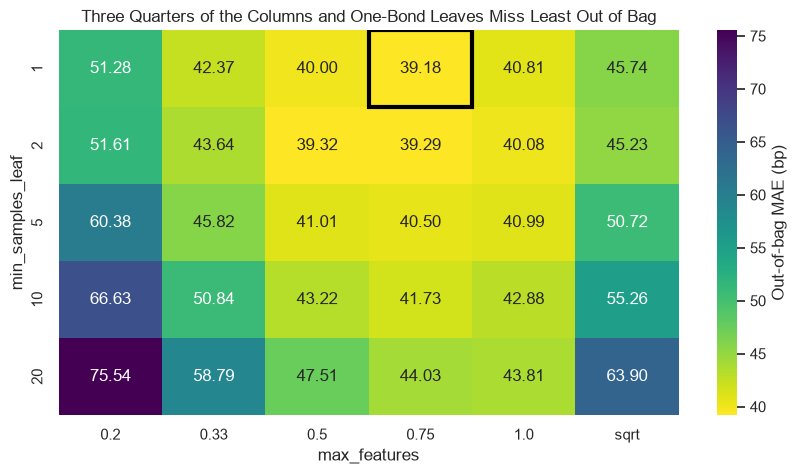

In [32]:
# the grid as an annotated heatmap, the lowest cell outlined
best_leaf, best_share = oob_grid.stack().idxmin()
print("Lowest out-of-bag MAE:", round(oob_grid.loc[best_leaf, best_share], 2), "bp at max_features", best_share,
      "and min_samples_leaf", best_leaf)
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(oob_grid, annot=True, fmt=".2f", cmap="viridis_r", cbar_kws={"label": "Out-of-bag MAE (bp)"}, ax=ax)
ax.add_patch(plt.Rectangle((oob_grid.columns.get_loc(best_share), oob_grid.index.get_loc(best_leaf)), 1, 1,
                           fill=False, edgecolor="black", linewidth=3))
ax.set_title("Three Quarters of the Columns and One-Bond Leaves Miss Least Out of Bag")
plt.show()

The default, 1.0 with one-bond leaves, misses by 40.81 bp out of bag; 0.75 with one-bond leaves by 39.18.

Few columns and big leaves together cost the most: 75.54 bp at 0.2 and 20-bond leaves.

Smooth is not the same as close: 10-bond leaves draw the generator's shape yet miss by 41.73 at 0.75.

## The Tuned Forest on the Folds

The settings were chosen on the same 615 bonds the folds now score, so the fold score flatters the tuned forest a little; Day 11 measures how much.

In [33]:
# the out-of-bag choice on the five folds, beside the line fold by fold
tuned = RandomForestRegressor(max_features=0.75, random_state=SEED, n_jobs=1)
scores = cross_validate(tuned, X, y, cv=folds, scoring=bp_scorer, return_train_score=True, n_jobs=1)
held["tuned forest"] = -scores["test_score"]
fitted["tuned forest"] = -scores["train_score"].mean()
pd.DataFrame({"line": held["line"], "tuned forest": held["tuned forest"]}, index=[1, 2, 3, 4, 5]).T

,1,2,3,4,5
line,30.09,36.17,61.78,39.30,41.24
tuned forest,29.96,32.62,60.76,31.37,40.38


The tuned forest misses by 39.02 bp, below the line in all five folds, by 0.1 to 7.9 bp.

**The tuned forest misses 2.7 bp less than the line on average, and less in every fold. Coupon has been left out of both; now give it to both.**

# Model Performance Comparison

## Without and With Coupon

**Predict 5**

With coupon the line's miss falls from 41.72 to 37.19 bp.

Q. Write down the tuned forest's held-out MAE with coupon.

In [34]:
# coupon added to both kinds of input, then four models on the same five folds
X_coupon = X.assign(coupon=train["coupon"])
LINE_X_COUPON = LINE_X.assign(coupon=train["coupon"])
line_coupon = make_model(LinearRegression(), LINE_NUMBERS + ["coupon"])
held_coupon = {"line": -cross_validate(line_coupon, LINE_X_COUPON, y, cv=folds, scoring=bp_scorer, n_jobs=1)["test_score"]}
for name, model in [("full tree", full_tree), ("forest", forest), ("tuned forest", tuned)]:
    held_coupon[name] = -cross_validate(model, X_coupon, y, cv=folds, scoring=bp_scorer, n_jobs=1)["test_score"]

In [35]:
# each model's mean held-out miss in bp, without and with coupon, and the tuned forest minus the line, fold by fold
comparison = pd.DataFrame({"without coupon": {name: held[name].mean() for name in held_coupon},
                           "with coupon": {name: held_coupon[name].mean() for name in held_coupon}})
print("With coupon, tuned forest minus line, by fold:", (held_coupon["tuned forest"] - held_coupon["line"]).round(1))
comparison

With coupon, tuned forest minus line, by fold: [-0.1  2.5 -0.2 -1.7  1.2]


,without coupon,with coupon
line,41.72,37.19
full tree,51.93,49.33
forest,40.23,38.69
tuned forest,39.02,37.53


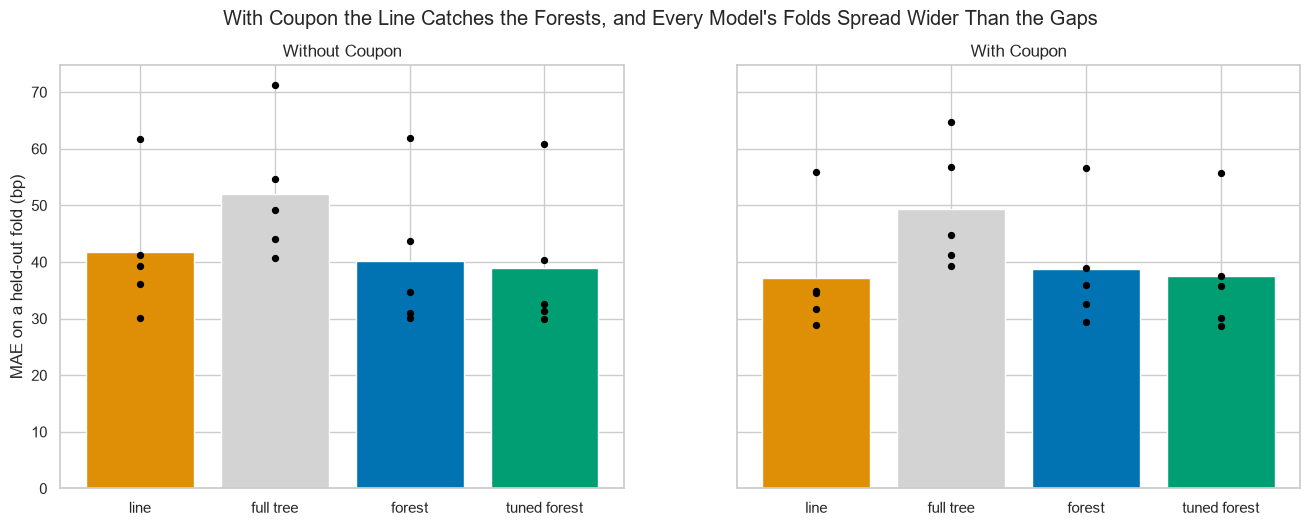

In [36]:
# Course 4's bars with fold dots: each model's mean as a bar, its five folds as dots
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
for ax, table, title in [(axes[0], held, "Without Coupon"), (axes[1], held_coupon, "With Coupon")]:
    names = list(held_coupon)
    ax.bar(names, [table[name].mean() for name in names], color=["C1", "lightgray", "C0", "C2"])
    for name in names:
        ax.scatter([name] * 5, table[name], color="black", s=18, zorder=3)
    ax.set_title(title)
axes[0].set_ylabel("MAE on a held-out fold (bp)")
fig.suptitle("With Coupon the Line Catches the Forests, and Every Model's Folds Spread Wider Than the Gaps")
plt.show()

Coupon lowers the line by 4.5 bp and the tuned forest by 1.5.

With coupon the line leads the tuned forest by 0.3 bp, while the forest misses less in 3 of the 5 folds: a tie, well inside the spread of the folds.

**Coupon carries part of the spread outright, so the line no longer needs the bends the trees find.**

# The Split by Issuer

## Folds That Keep Issuers Whole

Course 4's Day 5 `GroupKFold` keeps each issuer's bonds in one fold, so every held-out fold holds only issuers its model has never seen.

In [37]:
# five folds that keep issuers whole, and a model's miss in bp on each
by_issuer = GroupKFold(n_splits=5)
print("Bonds per fold:", [len(rows) for fit_rows, rows in by_issuer.split(X, y, groups=train["ticker"])])

def issuer_mae(model, rows):
    return -cross_validate(model, rows, y, cv=by_issuer, groups=train["ticker"], scoring=bp_scorer, n_jobs=1)["test_score"]

Bonds per fold: [123, 123, 123, 123, 123]


In [38]:
# the models on new issuers, without and with coupon
issuer_held = {"line": issuer_mae(line, LINE_X), "full tree": issuer_mae(full_tree, X),
               "forest": issuer_mae(forest, X), "tuned forest": issuer_mae(tuned, X)}
issuer_coupon = {"line": issuer_mae(line_coupon, LINE_X_COUPON), "full tree": issuer_mae(full_tree, X_coupon),
                 "forest": issuer_mae(forest, X_coupon), "tuned forest": issuer_mae(tuned, X_coupon)}
pd.DataFrame({"without coupon": {name: issuer_held[name].mean() for name in issuer_held},
              "with coupon": {name: issuer_coupon[name].mean() for name in issuer_coupon}})

,without coupon,with coupon
line,45.76,39.77
full tree,56.52,52.15
forest,45.19,41.31
tuned forest,43.37,40.51


A new issuer costs every model 4 to 5 bp without coupon, and 2.6 to 3.0 bp with it.

Without coupon the tuned forest still leads the line, 43.37 bp against 45.76; with coupon the line leads again.

Q. Fold by fold, how often does the tuned forest miss less than the line?

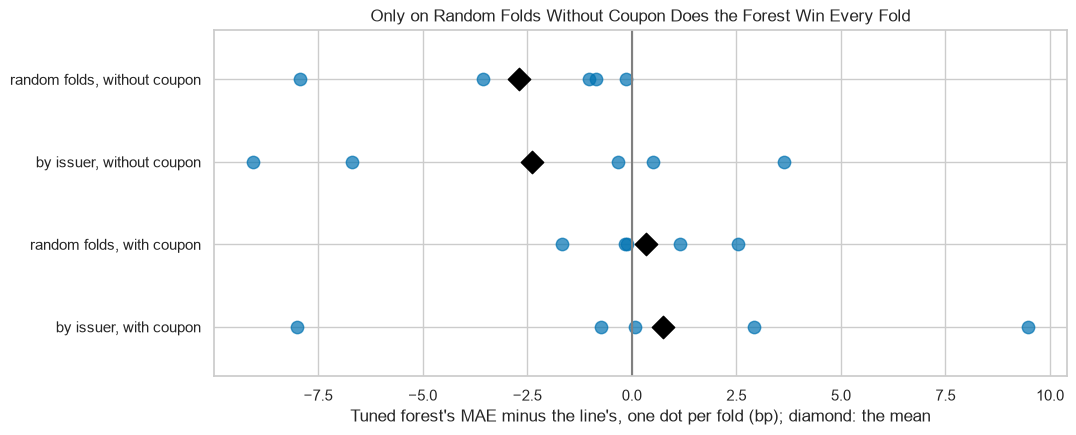

In [39]:
# the tuned forest's miss minus the line's on each fold, in four settings; left of zero the forest misses less
gaps = {"random folds, without coupon": held["tuned forest"] - held["line"],
        "by issuer, without coupon": issuer_held["tuned forest"] - issuer_held["line"],
        "random folds, with coupon": held_coupon["tuned forest"] - held_coupon["line"],
        "by issuer, with coupon": issuer_coupon["tuned forest"] - issuer_coupon["line"]}
fig, ax = plt.subplots(figsize=(11, 4.5))
for row, name in enumerate(gaps):
    ax.scatter(gaps[name], [row] * 5, s=80, color="C0", alpha=0.7)
    ax.scatter(gaps[name].mean(), row, marker="D", s=130, color="black", zorder=3)
ax.axvline(0, color="gray")
ax.set(yticks=range(4), yticklabels=list(gaps), ylim=(3.6, -0.6))
ax.set_xlabel("Tuned forest's MAE minus the line's, one dot per fold (bp); diamond: the mean")
ax.set_title("Only on Random Folds Without Coupon Does the Forest Win Every Fold")
plt.show()

This is a **difference strip**: one dot per fold for the gap between two models, so a mean can be read against its folds.

All five dots sit left of zero only in the first row.

By issuer with coupon the folds run from 8.0 bp in the forest's favour to 9.5 against it.

**The forest's edge is real on random folds without coupon and fades everywhere else into the spread between folds.**

# Reading the Tuned Forest

## What the Forest Leans On

Day 4 read permutation importance on unseen rows; here each column is shuffled in each held-out fold and the rise in the miss is measured in bp.

In [40]:
# in each fold: the tuned forest fitted on four folds, each column shuffled ten times in the fifth, the rise in bp
importance = []
for fit_rows, held_rows in folds.split(X):
    fold_forest = RandomForestRegressor(max_features=0.75, random_state=SEED, n_jobs=1).fit(X.iloc[fit_rows], y.iloc[fit_rows])
    result = permutation_importance(fold_forest, X.iloc[held_rows], y.iloc[held_rows], scoring=bp_scorer,
                                    n_repeats=10, random_state=SEED, n_jobs=1)
    importance.append(result.importances_mean)
importance = pd.DataFrame(importance, columns=X.columns).T
importance.mean(axis=1).sort_values(ascending=False).head(5)

score               100.69
years_to_maturity    12.34
duration              6.31
Telecom               0.73
Technology            0.37
dtype: float64

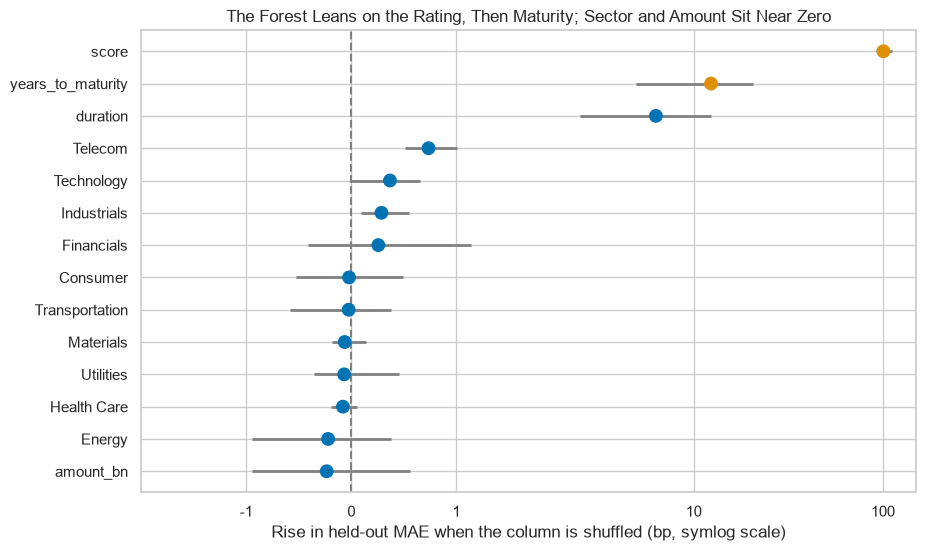

In [41]:
# each column's mean rise as a dot, its five folds as a whisker; the generator's two inputs in orange
order = importance.mean(axis=1).sort_values().index
colours = ["C1" if column in ["score", "years_to_maturity"] else "C0" for column in order]
fig, ax = plt.subplots(figsize=(10, 6))
ax.hlines(order, importance.loc[order].min(axis=1), importance.loc[order].max(axis=1), color="gray", linewidth=2)
ax.scatter(importance.loc[order].mean(axis=1), order, color=colours, s=80, zorder=3)
ax.axvline(0, color="gray", linestyle="--")
ax.set_xscale("symlog")
ax.set_xticks([-1, 0, 1, 10, 100], [-1, 0, 1, 10, 100])
ax.set_xlim(-2, 150)
ax.set_xlabel("Rise in held-out MAE when the column is shuffled (bp, symlog scale)")
ax.set_title("The Forest Leans on the Rating, Then Maturity; Sector and Amount Sit Near Zero")
plt.show()

Shuffling the rating score costs 100.7 bp; years 12.3 and duration 6.3, a near-copy of years.

Every sector and the amount sit within 1 bp of zero: the generator never uses them.

An importance says what this forest leans on, an association in this file, never a driver of spreads.

## The Widest Bonds

`cross_val_predict` (Course 4's Day 15) gives each training bond its fitted value from the fold that held it out.

In [42]:
# each training bond's out-of-fold fitted spread in bp, from the tuned forest and from the line
oof = train[["issuer", "cusip", "rating", "grade", "oas"]].copy()
oof["forest"] = np.exp(cross_val_predict(tuned, X, y, cv=folds, n_jobs=1))
oof["line"] = np.exp(cross_val_predict(line, LINE_X, y, cv=folds, n_jobs=1))
oof.nlargest(6, "oas")

,issuer,cusip,rating,grade,oas,forest,line
386,Zephane Utilities,99072UAF5,B,High Yield,2074,599.49,373.05
789,Praximer Energy,99145PAB8,B-,High Yield,1718,716.16,497.66
365,Feskovar Devices,99069RAC4,CCC+,High Yield,1551,519.70,722.48
47,Calderby Retail,99009JAA9,B,High Yield,1446,478.94,402.71
197,Praxiskan Finance,99038MAD1,CCC+,High Yield,1215,688.63,890.41
195,Praxiskan Finance,99038MAB5,CCC+,High Yield,974,817.79,809.60


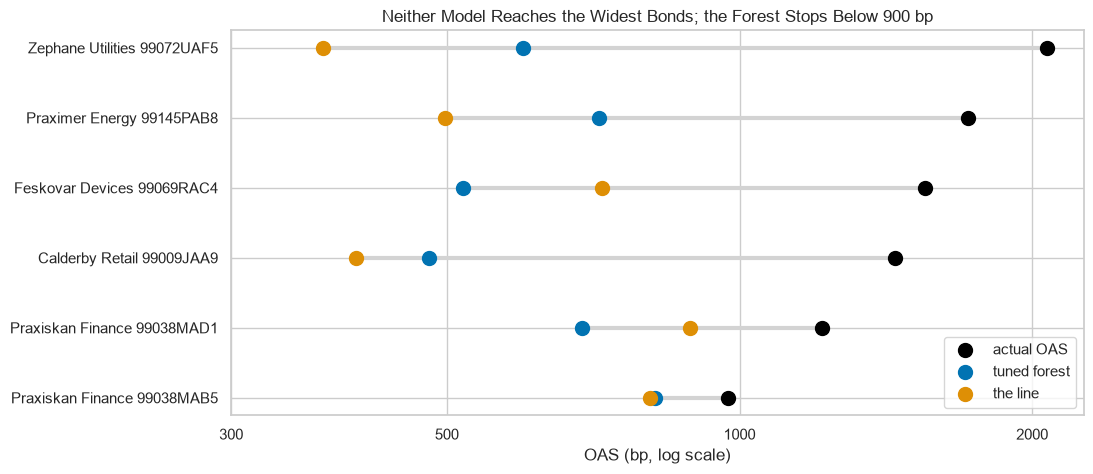

In [43]:
# the six widest bonds: actual OAS, the forest's and the line's fitted spreads, joined by a gray bar
widest = oof.nlargest(6, "oas").iloc[::-1]
labels = widest["issuer"] + " " + widest["cusip"]
fig, ax = plt.subplots(figsize=(11, 5))
ax.hlines(labels, widest[["forest", "line"]].min(axis=1), widest["oas"], color="lightgray", linewidth=3)
ax.scatter(widest["oas"], labels, s=100, color="black", label="actual OAS", zorder=3)
ax.scatter(widest["forest"], labels, s=100, color="C0", label="tuned forest", zorder=3)
ax.scatter(widest["line"], labels, s=100, color="C1", label="the line", zorder=3)
ax.set_xscale("log")
ax.set_xticks([300, 500, 1000, 2000], [300, 500, 1000, 2000])
ax.minorticks_off()
ax.set_xlabel("OAS (bp, log scale)")
ax.set_title("Neither Model Reaches the Widest Bonds; the Forest Stops Below 900 bp")
ax.legend(loc="lower right")
plt.show()

In [44]:
# the widest fitted spread each model gives, and the mean miss in bp by grade
print("Widest fitted spread, forest:", round(oof["forest"].max(), 1), " line:", round(oof["line"].max(), 1), "bp")
oof["forest miss"] = (oof["oas"] - oof["forest"]).abs()
oof["line miss"] = (oof["oas"] - oof["line"]).abs()
oof.groupby("grade")[["forest miss", "line miss"]].mean()

Widest fitted spread, forest: 817.8  line: 1025.9 bp


,forest miss,line miss
grade,,
High Yield,77.72,85.89
Investment Grade,18.80,18.65


Zephane Utilities `99072UAF5`, B at 2,074 bp, gets 599.5 from the forest and 373.1 from the line.

A leaf can only average spreads it has seen, so the forest's widest fitted spread is 817.8 bp against the line's 1,025.9.

The forest misses high yield bonds by 77.7 bp against the line's 85.9, and investment grade by 18.8 against 18.6: the whole gain is high yield.

## How the Miss Is Shared

In [45]:
# the share of the total miss held by the largest 5 and the largest 62 misses (a tenth of the bonds), in percent
for name in ["forest miss", "line miss"]:
    largest_first = oof[name].sort_values(ascending=False)
    print(name, " largest 5:", round(largest_first.head(5).sum() / largest_first.sum() * 100, 1),
          " largest 62:", round(largest_first.head(62).sum() / largest_first.sum() * 100, 1))

forest miss  largest 5: 20.8  largest 62: 49.2
line miss  largest 5: 20.7  largest 62: 52.4


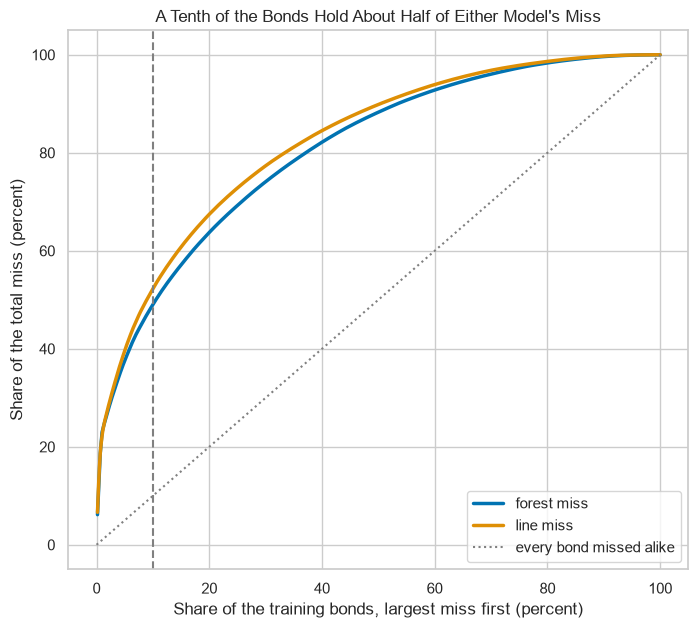

In [46]:
# the running share of the total miss against the share of bonds, largest misses first
share_of_bonds = np.arange(1, len(oof) + 1) / len(oof) * 100
fig, ax = plt.subplots(figsize=(8, 7))
for name, colour in [("forest miss", "C0"), ("line miss", "C1")]:
    largest_first = oof[name].sort_values(ascending=False)
    ax.plot(share_of_bonds, largest_first.cumsum() / largest_first.sum() * 100, color=colour, linewidth=2.5, label=name)
ax.plot([0, 100], [0, 100], color="gray", linestyle=":", label="every bond missed alike")
ax.axvline(10, color="gray", linestyle="--")
ax.set(xlabel="Share of the training bonds, largest miss first (percent)", ylabel="Share of the total miss (percent)")
ax.set_title("A Tenth of the Bonds Hold About Half of Either Model's Miss")
ax.legend(loc="lower right")
plt.show()

This is a **concentration curve**: the further it bows above the diagonal, the more of the total miss sits in a few bonds.

The largest tenth of the misses holds 49.2 percent of the forest's total and 52.4 percent of the line's.

The five largest alone hold about a fifth of either.

A miss is the model's, never a view on a bond.

# Insights and Conclusion

One full tree memorises: it misses its own bonds by nothing and a held-out bond by 51.9 bp.

Averaging cancels most of that, and eight trees pass the line.

The out-of-bag score lands within 0.6 bp of the folds from one fit.

Columns per split matter more than leaf size here, and `"sqrt"` hides the rating from most first questions.

Without coupon the tuned forest leads the line by 2.7 bp, and by 2.4 on new issuers; with coupon the two tie.

The forest leans on the rating, then maturity, and cannot reach the widest bonds.

**Week 1 ends with an average of trees that describes these bonds a little better than a line, and an honest measure of how little. Week 2 grows trees one after another.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Fit regression trees, bagging and forests and score them in bp on Course 4's folds.
* Read fitted folds against held-out folds with `return_train_score=True`.
* Average a forest's trees one at a time with `.estimators_`.
* Read a regression forest's `.oob_prediction_` and `.oob_score_`, and choose settings by out-of-bag error.
* Compare models without and with a column, and on folds that keep issuers whole.
* Read permutation importance in bp and find where a model misses most.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [47]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**A Third of the Columns**

Q. Cross-validate `RandomForestRegressor(max_features=0.33, random_state=SEED, n_jobs=1)` on `X` with `folds` and `bp_scorer`, and store its mean held-out MAE in bp in `ex1_mae_bp`.

In [48]:
# a forest offered a third of the columns at each split, on the same five folds
third = RandomForestRegressor(max_features=0.33, random_state=SEED, n_jobs=1)
ex1_mae_bp = -cross_validate(third, X, y, cv=folds, scoring=bp_scorer, n_jobs=1)["test_score"].mean()
print(ex1_mae_bp)

42.04165291515975


A third of the columns misses by 42.04 bp, behind the default forest and the line.

In [49]:
check("Exercise 1 the held-out MAE", ex1_mae_bp, 42.04165291515975)

Exercise 1 the held-out MAE: correct


### Exercise 2

**Investment Grade Only**

Q. Keep the 404 investment grade training bonds. Cross-validate the line (`line` on `LINE_X`) and the tuned forest (`tuned` on `X`) on them with `folds`, and store their mean held-out MAE in bp in `ex2_line_bp` and `ex2_forest_bp`.

In [50]:
# the investment grade bonds only, on the same folds
ig = train["grade"] == "Investment Grade"
print(ig.sum(), "bonds")
ex2_line_bp = -cross_validate(line, LINE_X[ig], y[ig], cv=folds, scoring=bp_scorer, n_jobs=1)["test_score"].mean()
ex2_forest_bp = -cross_validate(tuned, X[ig], y[ig], cv=folds, scoring=bp_scorer, n_jobs=1)["test_score"].mean()
print(ex2_line_bp, ex2_forest_bp)

404 bonds
18.32010098062546 18.898297933533758


On investment grade bonds alone the line misses by 18.32 bp and the tuned forest by 18.90: the forest's gain was high yield.

In [51]:
check("Exercise 2 the line", ex2_line_bp, 18.32010098062546)
check("Exercise 2 the tuned forest", ex2_forest_bp, 18.898297933533758)

Exercise 2 the line: correct
Exercise 2 the tuned forest: correct


### Exercise 3

**A Table of Fold Scores**

Q. Write `bp_table(scores)`, which takes a dictionary of five-fold MAE arrays and returns a DataFrame with one row per model and the columns `mean` and `std` (pandas' standard deviation), rounded to 1 decimal. Store `bp_table(held).to_dict()` in `ex3_table`.

In [52]:
# one row per model: the mean and the standard deviation of its five fold scores, in bp
def bp_table(scores):
    return pd.DataFrame(scores).agg(["mean", "std"]).T.round(1)

ex3_table = bp_table(held).to_dict()
bp_table(held)

,mean,std
line,41.70,12.00
full tree,51.90,12.00
depth-4 tree,45.20,13.10
bagging,40.30,12.90
forest,40.20,13.20
tuned forest,39.00,12.80


In [53]:
check("Exercise 3 the table", ex3_table,
      {"mean": {"line": 41.7, "full tree": 51.9, "depth-4 tree": 45.2, "bagging": 40.3, "forest": 40.2, "tuned forest": 39.0},
       "std": {"line": 12.0, "full tree": 12.0, "depth-4 tree": 13.1, "bagging": 12.9, "forest": 13.2, "tuned forest": 12.8}})

Exercise 3 the table: correct


### Exercise 4: AI check

**The Forest That Reopened the Test Bonds**

You asked an AI assistant for a function that cross-validates the default forest on the benchmark bonds.
This came back.
It runs, and it reports a smaller miss than the forest's 40.23 bp.
Test it, then find the one bug.

In [54]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def forest_cv():
    # the default forest on the benchmark bonds, five folds, MAE in bp
    rows = data
    X_rows = pd.concat([rows[NUMBERS], pd.get_dummies(rows["sector"], dtype=float)], axis=1)
    scores = cross_validate(RandomForestRegressor(random_state=SEED, n_jobs=1), X_rows, rows["log_oas"], cv=folds,
                            scoring=bp_scorer, n_jobs=1)
    return rows, -scores["test_score"].mean()

ai_rows, ai_mae = forest_cv()
print(len(ai_rows), "bonds,", round(ai_mae, 2), "bp")

821 bonds, 38.51 bp


In [55]:
# the test: the forest is fitted and scored on Course 4's 615 training bonds and no others
assert set(ai_rows["cusip"]) == set(train["cusip"]), "the folds hold bonds outside Course 4's training bonds"

AssertionError: the folds hold bonds outside Course 4's training bonds

Q. How many of Course 4's test bonds did the function reopen? Store the number in `ex4_reopened`, fix the function, and store the fixed function's MAE in bp in `ex4_mae_bp`.

In [56]:
# the fix: the training bonds, not all 821; then the bonds the buggy version reopened
def forest_cv():
    # the default forest on Course 4's training bonds, five folds, MAE in bp
    rows = train
    X_rows = pd.concat([rows[NUMBERS], pd.get_dummies(rows["sector"], dtype=float)], axis=1)
    scores = cross_validate(RandomForestRegressor(random_state=SEED, n_jobs=1), X_rows, rows["log_oas"], cv=folds,
                            scoring=bp_scorer, n_jobs=1)
    return rows, -scores["test_score"].mean()

ex4_reopened = len(set(ai_rows["cusip"]) - set(train["cusip"]))
fixed_rows, ex4_mae_bp = forest_cv()
assert set(fixed_rows["cusip"]) == set(train["cusip"])
print(ex4_reopened, ex4_mae_bp)

206 40.22844973028873


In [57]:
check("Exercise 4 the test bonds reopened", ex4_reopened, 206)
check("Exercise 4 the fixed MAE", ex4_mae_bp, 40.22844973028873)

Exercise 4 the test bonds reopened: correct
Exercise 4 the fixed MAE: correct


## Congratulations!

You took Week 1's forests to the bonds and scored them against Course 4's line on its own folds.
You watched one tree memorise, a hundred average past the line, and the out-of-bag rows agree with the folds from a single fit.
You tuned a forest without touching a fold, then tested its edge with coupon and on new issuers, and saw how small an honest edge can be.
That habit, a gain measured fold by fold, is what a desk needs before it trusts any model.
Week 2 grows trees one after another, each fixing what the last one missed.

[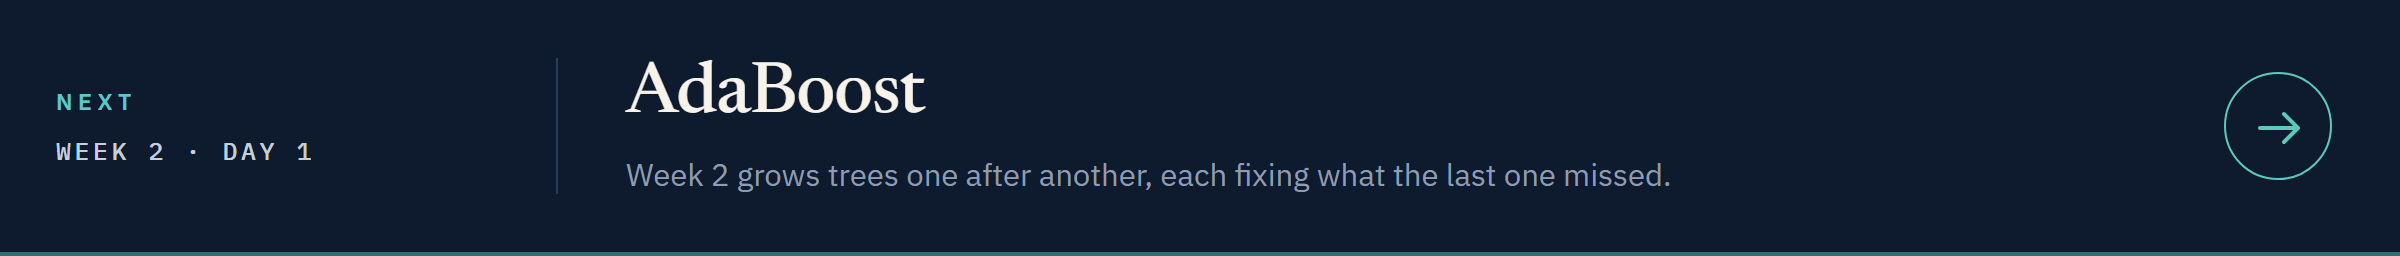](../../week2/day1/06_adaboost.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week2/day1/06_adaboost.ipynb)